# 05 · SHAP ile Yorumlama ve Eksiklik Göstergesinin Etiği

**Görseldeki 4. adım:** *Model hangi özniteliklere dayanıyor? Açıklanabilirlik.*

04'te son modeli seçtik: **RF·C** (rastgele orman + medyan doldurma + 7 grup eksiklik göstergesi). İyi kalibre ama zayıf bir model (ROC-AUC ≈ 0.70). Bu defterde modelin **neye bakarak** karar verdiğini inceliyoruz:

| Soru | Yöntem |
|---|---|
| Model genel olarak hangi özniteliklere dayanıyor? | Ortalama \|SHAP\|, öznitelik ve grup düzeyinde |
| Bir öznitelik riski hangi yönde, ne kadar değiştiriyor? | Arı kovanı (beeswarm) ve bağımlılık grafikleri |
| "Soruyu cevaplamamak" modelde ne kadar ağırlık taşıyor? | SHAP katkısını gözlenen / doldurulmuş / gösterge olarak ayırma |
| Tek bir hastanın tahmini nasıl oluşuyor? | Hasta düzeyinde katkı grafikleri |
| Bu davranışa güvenmeli miyiz? | Etik tartışma |

**SHAP nedir?** Her hasta için tahmini, özniteliklerin katkılarına böler:

$$\text{tahmin edilen risk} = \text{taban değer} + \sum_j \text{SHAP}_j$$

Taban değer, eğitim verisindeki ortalama tahmindir (≈ %6.4). Pozitif SHAP riski artırır, negatif SHAP azaltır. Rastgele ormanda `TreeExplainer` bu değerleri **olasılık ölçeğinde** ve tam olarak hesaplar; bu yüzden katkıları doğrudan **yüzde puan** olarak okuyabiliriz.

> **SHAP neyi söylemez?** SHAP *modeli* açıklar, *hastalığı* değil. "HK yılı riski artırıyor" cümlesi "model HK yılı yüksek olanlara daha yüksek risk veriyor" demektir; nedensellik iddiası değildir. Ayrıca model zayıf olduğu için açıkladığımız sinyal de zayıftır.

In [1]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from pathlib import Path
from scipy import stats

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.utils import (load_raw, clean, build_pipeline, missing_indicators, wilson_ci,
                       FEATURES, NUMERIC, TARGET, MISSING_GROUPS)

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = Path("../results/figures")
TAB = Path("../results/tables")

df = clean(load_raw())
X = df[FEATURES]
y = df[TARGET].to_numpy()
prev = y.mean()
print(f"{len(y)} hasta, {y.sum()} biyopsi+ (%{prev*100:.1f}) · shap {shap.__version__}")

858 hasta, 55 biyopsi+ (%6.4) · shap 0.54.1


## 1. Dışarıda bırakılmış (out-of-fold) SHAP değerleri

SHAP değerlerini modelin **eğitildiği** hastalarda hesaplamak, ezberlenmiş örüntüleri de "önemli" gösterebilir. 04'teki ilkeyi burada da koruyoruz: her hastanın SHAP değerleri, o hastayı **eğitimde hiç görmemiş** bir modelden gelir.

1. Veriyi 5 kata böl. Modeli 4 katla eğit, kalan kattaki hastaların SHAP değerlerini hesapla.
2. Bunu 04'teki **aynı** 10 bölmeyle tekrarla (aynı tohumlar).
3. Her hasta için 10 tekrarın SHAP değerlerini **ortala**.

Bölmeler ve model 04 ile aynı olduğu için `taban + Σ SHAP` tam olarak 04'teki ortalama OOF tahmini verir. Aşağıda bunu doğruluyoruz.

Grafiklerde Türkçe öznitelik adları ve **ham (dönüştürülmemiş) değerler** kullanılıyor; model ise log1p + doldurma + standartlaştırma sonrası değerleri görüyor.

⏱️ Yaklaşık 1–2 dakika.

In [2]:
TR = {
    "Age": "Yaş", "Number of sexual partners": "Partner sayısı", "First sexual intercourse": "İlk ilişki yaşı",
    "Num of pregnancies": "Gebelik sayısı", "Smokes (years)": "Sigara (yıl)", "Smokes (packs/year)": "Sigara (paket/yıl)",
    "Hormonal Contraceptives (years)": "HK (yıl)", "IUD (years)": "RİA (yıl)", "STDs (number)": "CYBH sayısı",
    "STDs:condylomatosis": "Kondilomatoz", "STDs:syphilis": "Sifiliz", "STDs:HIV": "HIV",
    "Dx:Cancer": "Dx: Kanser", "Dx:CIN": "Dx: CIN", "Dx:HPV": "Dx: HPV",
}
OZ = [TR[f] for f in FEATURES]                      # 15 öznitelik
GOST = [f"Eksik: {g}" for g in MISSING_GROUPS]      # 7 grup göstergesi
ADLAR = OZ + GOST

# Grafiklerde gösterilecek değerler: ham öznitelikler (eksikler NaN) + 0/1 göstergeler
D = pd.concat([X.rename(columns=TR), missing_indicators(df).set_axis(GOST, axis=1)], axis=1)
EKSIK = X.isna().to_numpy()                         # (858, 15): bu değer doldurulmuş mu?

rf = lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0)


def oof_shap(estimator, X, y, n_repeats=10, n_splits=5, seed=42):
    # Her hasta için, o hastayı görmemiş modelden SHAP değerleri (pozitif sınıf, olasılık ölçeği).
    # Döndürür: S (tekrar, hasta, öznitelik) ve taban (tekrar, hasta). Bölmeler 04'teki oof_predictions ile aynıdır.
    n_feat = clone(estimator).fit(X, y)[:-1].transform(X.iloc[:2]).shape[1]
    S = np.empty((n_repeats, len(y), n_feat))
    taban = np.empty((n_repeats, len(y)))
    for r in range(n_repeats):
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        for tr, te in cv.split(X, y):
            pipe = clone(estimator).fit(X.iloc[tr], y[tr])
            ex = shap.TreeExplainer(pipe[-1])
            S[r, te] = ex(pipe[:-1].transform(X.iloc[te])).values[..., 1]
            taban[r, te] = np.ravel(ex.expected_value)[1]
    return S, taban


S_C, taban_C = oof_shap(build_pipeline(rf(), group=True), X, y)    # RF·C: 15 öznitelik + 7 gösterge
S_A, taban_A = oof_shap(build_pipeline(rf()), X, y)                # RF·A: yalnızca 15 öznitelik (6. bölüm için)
SV = pd.DataFrame(S_C.mean(axis=0), columns=ADLAR)                 # hasta başına ortalama SHAP
taban = taban_C.mean(axis=0)
P = taban + SV.sum(axis=1).to_numpy()                              # = ortalama OOF tahmin

print(f"SHAP matrisi: {SV.shape[0]} hasta × {SV.shape[1]} sütun")
print(f"Taban değer: %{taban.mean()*100:.2f} (gözlenen pozitif oranı %{prev*100:.2f})")
print(f"taban + Σ SHAP ile hesaplanan OOF tahmin → ROC-AUC {roc_auc_score(y, P):.3f}, PR-AUC {average_precision_score(y, P):.3f}"
      "  (04: 0.700 / 0.157)")

SHAP matrisi: 858 hasta × 22 sütun
Taban değer: %6.41 (gözlenen pozitif oranı %6.41)
taban + Σ SHAP ile hesaplanan OOF tahmin → ROC-AUC 0.700, PR-AUC 0.157  (04: 0.700 / 0.157)


**Doğrulama:** Taban değer gözlenen pozitif oranına eşit (%6.41) ve `taban + Σ SHAP`, 04'teki ROC-AUC (0.700) ve PR-AUC (0.157) değerlerini birebir veriyor. Yani aşağıda açıkladığımız şey, 04'te değerlendirdiğimiz tahminlerin **tam** ayrıştırması; ayrı bir model ya da yaklaşık bir açıklama değil.

## 2. Model genel olarak neye dayanıyor?

**Ortalama |SHAP|:** bir özniteliğin, hastaların tahminini ortalama kaç **yüzde puan** oynattığı. Yön taşımaz, yalnızca büyüklüğü gösterir. Her tekrarda ayrı hesaplanıp 10 tekrarın ortalaması alınır. Hata çubukları 10 tekrar arasındaki en küçük ve en büyük değerdir; sıralamanın bölmeye ne kadar duyarlı olduğunu gösterir.

In [3]:
onem_tekrar = pd.DataFrame(np.abs(S_C).mean(axis=1) * 100, columns=ADLAR)      # (10 tekrar, 22): yüzde puan
onem = pd.DataFrame({
    "ort |SHAP| (yp)": onem_tekrar.mean().to_numpy(),
    "tekrar min": onem_tekrar.min().to_numpy(), "tekrar max": onem_tekrar.max().to_numpy(),
    "ort SHAP (yp)": SV.mean().to_numpy() * 100,
    "tür": ["öznitelik"] * len(OZ) + ["eksiklik göstergesi"] * len(GOST),
}, index=ADLAR).sort_values("ort |SHAP| (yp)", ascending=False)
onem["pay %"] = onem["ort |SHAP| (yp)"] / onem["ort |SHAP| (yp)"].sum() * 100
onem.to_csv(TAB / "05_shap_onem.csv", encoding="utf-8-sig")

# Sıralama tekrarlar arasında ne kadar kararlı?
rho = [stats.spearmanr(onem_tekrar.iloc[i], onem_tekrar.iloc[j])[0] for i in range(10) for j in range(i + 1, 10)]
print(f"Tekrar çiftleri arasında önem sıralaması Spearman ρ: ort {np.mean(rho):.3f}, en düşük {np.min(rho):.3f}")
onem.round(3)

Tekrar çiftleri arasında önem sıralaması Spearman ρ: ort 0.993, en düşük 0.985


,ort |SHAP| (yp),tekrar min,tekrar max,ort SHAP (yp),tür,pay %
HK (yıl),0.968,0.914,1.015,0.039,öznitelik,12.656
CYBH sayısı,0.745,0.722,0.781,0.018,öznitelik,9.742
Yaş,0.663,0.625,0.736,0.027,öznitelik,8.667
İlk ilişki yaşı,0.616,0.567,0.667,0.006,öznitelik,8.050
Partner sayısı,0.549,0.520,0.579,0.013,öznitelik,7.181
Gebelik sayısı,0.542,0.521,0.578,-0.026,öznitelik,7.083
Eksik: HK,0.491,0.472,0.505,-0.044,eksiklik göstergesi,6.417
Eksik: Gebelik,0.413,0.386,0.455,0.012,eksiklik göstergesi,5.396
Kondilomatoz,0.395,0.369,0.430,-0.013,öznitelik,5.168
Dx: HPV,0.395,0.376,0.445,-0.011,öznitelik,5.165


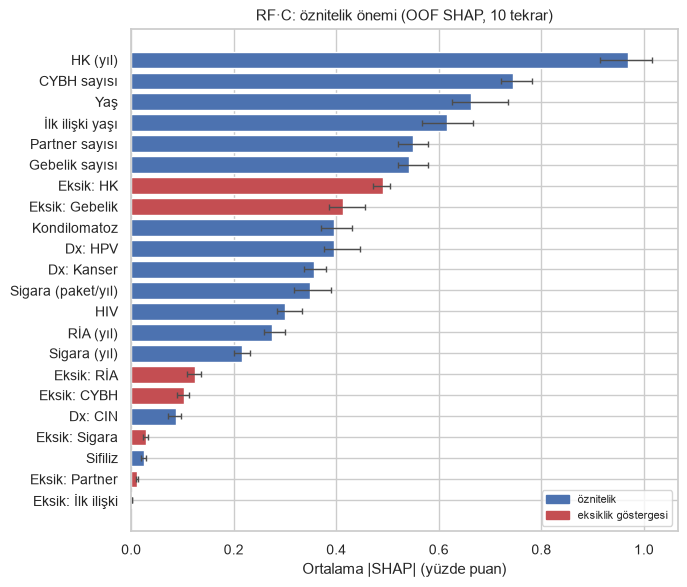

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
o = onem.iloc[::-1]
renk = {"öznitelik": sns.color_palette()[0], "eksiklik göstergesi": sns.color_palette()[3]}
ax.barh(o.index, o["ort |SHAP| (yp)"], color=[renk[t] for t in o["tür"]],
        xerr=[np.clip(o["ort |SHAP| (yp)"] - o["tekrar min"], 0, None), np.clip(o["tekrar max"] - o["ort |SHAP| (yp)"], 0, None)],
        error_kw={"elinewidth": 1, "capsize": 2, "ecolor": "0.3"})
ax.set_xlabel("Ortalama |SHAP| (yüzde puan)")
ax.set_title("RF·C: öznitelik önemi (OOF SHAP, 10 tekrar)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in renk.values()], labels=list(renk), fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "05_shap_onem.png", dpi=150)
plt.show()

### Soru grubu düzeyinde önem

Tek tek öznitelikler ilişkili olabilir (ör. sigara yılı ve paket/yıl) ve SHAP katkıyı aralarında böler. Bu yüzden 01'deki soru gruplarına göre de bakıyoruz: bir grubun SHAP değerleri **toplanır**, sonra mutlak değerin ortalaması alınır. Eksiklik göstergeleri ayrı bir grup olarak tutuluyor.

In [5]:
GRUP = {
    "Demografi / cinsel öykü": ["Yaş", "Partner sayısı", "İlk ilişki yaşı", "Gebelik sayısı"],
    "Sigara": ["Sigara (yıl)", "Sigara (paket/yıl)"],
    "Hormonal kontraseptif": ["HK (yıl)"],
    "RİA": ["RİA (yıl)"],
    "CYBH": ["CYBH sayısı", "Kondilomatoz", "Sifiliz", "HIV"],
    "Önceki tanılar (Dx)": ["Dx: Kanser", "Dx: CIN", "Dx: HPV"],
    "Eksiklik göstergeleri": GOST,
}
idx = {g: [ADLAR.index(c) for c in cols] for g, cols in GRUP.items()}
grup_onem = pd.DataFrame({"sütun": {g: len(c) for g, c in GRUP.items()},
                          "ort |SHAP| (yp)": {g: np.abs(S_C[:, :, i].sum(axis=2)).mean() * 100 for g, i in idx.items()}}
                         ).sort_values("ort |SHAP| (yp)", ascending=False)
grup_onem["pay %"] = grup_onem["ort |SHAP| (yp)"] / grup_onem["ort |SHAP| (yp)"].sum() * 100
grup_onem.round(2)

,sütun,ort |SHAP| (yp),pay %
CYBH,4,1.38,22.75
Demografi / cinsel öykü,4,1.36,22.39
Hormonal kontraseptif,1,0.97,15.94
Önceki tanılar (Dx),3,0.83,13.63
Eksiklik göstergeleri,7,0.73,11.94
Sigara,2,0.54,8.85
RİA,1,0.27,4.50


**Yorum:**
- **Tek bir baskın öznitelik yok.** En önemli sütun olan HK yılı bile tahminleri ortalama ≈1 yüzde puan oynatıyor; ilk altı öznitelik birbirine yakın (≈0.5–1.0 yp). Bu, 04'teki dar tahmin aralığıyla ve zayıf sinyalle uyumlu.
- **Sıralama kararlı.** 10 tekrar arasında önem sıralamasının Spearman korelasyonu ≈0.99; bulgular tek bir bölmeye bağlı değil.
- **Grup düzeyinde** CYBH (≈%23) ve demografi / cinsel öykü (≈%22) başta, ardından hormonal kontraseptif (≈%16) ve önceki tanılar (≈%14) geliyor.
- **Eksiklik göstergeleri toplam önemin ≈%12'sini taşıyor**; sigaradan (≈%9) ve RİA'dan (≈%5) fazla. Bunun neredeyse tamamı iki göstergeden geliyor: `Eksik: HK` ve `Eksik: Gebelik`. Diğer beş gösterge ihmal edilebilir düzeyde.
- **`Eksik: Gebelik` beklenmedik biçimde 8. sırada.** 02'de gebelik sorusunu cevaplamayan 56 hastada pozitif oranı daha yüksekti (7/56, %12.5) ama bu fark çoklu test düzeltmesinden sonra anlamlı değildi. Model yine de bunu öğrenmiş: 7 pozitife dayanan kırılgan bir örüntü.

## 3. Yön ve büyüklük: arı kovanı grafiği

Her nokta bir hasta. Yatay konum SHAP değeri (sağ = riski artırıyor), renk özniteliğin **ham değeri** (kırmızı = yüksek, mavi = düşük). **Gri noktalar, değeri eksik olan (doldurulmuş) hastalardır.**

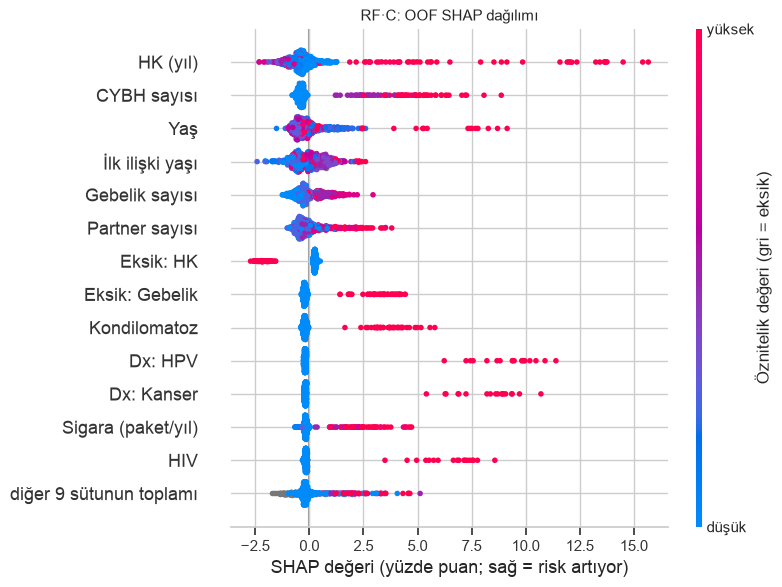

In [6]:
exp = shap.Explanation(values=SV.to_numpy() * 100, base_values=taban * 100, data=D.to_numpy(dtype=float), feature_names=ADLAR)
shap.plots.beeswarm(exp, max_display=14, show=False, plot_size=(8, 6))
fig = plt.gcf()
ax, cbar = fig.axes[0], fig.axes[-1]
ax.set_yticklabels([f"diğer {len(ADLAR) - 13} sütunun toplamı" if t.get_text().startswith("Sum of") else t.get_text()
                    for t in ax.get_yticklabels()])
cbar.set_ylabel("Öznitelik değeri (gri = eksik)")
cbar.set_yticklabels(["düşük", "yüksek"])
plt.sca(ax)
plt.xlabel("SHAP değeri (yüzde puan; sağ = risk artıyor)")
plt.title("RF·C: OOF SHAP dağılımı", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "05_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Yorum:**
- **Etkiler asimetrik:** Çoğu hasta için katkılar sıfıra yakın ve hafif negatif; küçük bir hasta grubunda ise büyük ve pozitif. Model riski az sayıda hastada belirgin şekilde **artırıyor**, geri kalanında hafifçe azaltıyor.
- **0/1 öznitelikler az hastada büyük etki yapıyor:** `Dx: HPV` ve `Dx: Kanser` pozitif olan 18'er hastada (16'sı aynı hasta) riski ≈6–11 yp artırıyor; HIV (18 hasta) ve kondilomatoz (44 hasta) ≈2–8 yp. Bunlar genel önem sıralamasında ortalarda, çünkü çok az hastayı etkiliyorlar; ama etkiledikleri hastada **en büyük** katkıyı veriyorlar.
- **`Eksik: HK` iki ayrı küme oluşturuyor:** soruyu cevaplamayanlarda ≈−2 yp (kırmızı küme, solda), cevaplayanlarda ≈+0.3 yp. Grafikte riski bu kadar tutarlı biçimde **düşüren** başka bir sütun yok.
- **`Eksik: Gebelik` ters yönde:** cevaplamayanlarda riski ≈+1.5–4.5 yp artırıyor.

## 4. Bağımlılık grafikleri: risk öznitelik değeriyle nasıl değişiyor?

En önemli dört sayısal öznitelik için SHAP değerini ham değere karşı çiziyoruz. Mavi noktalar soruyu cevaplayan hastalar; turuncu noktalar, altta tablosu verilen değer aralıklarındaki ortalama SHAP değeridir. **Kırmızı noktalar** değeri eksik olan hastalardır; modelin gördüğü değer medyan olduğu için sağda ayrı bir sütunda gösteriliyorlar.

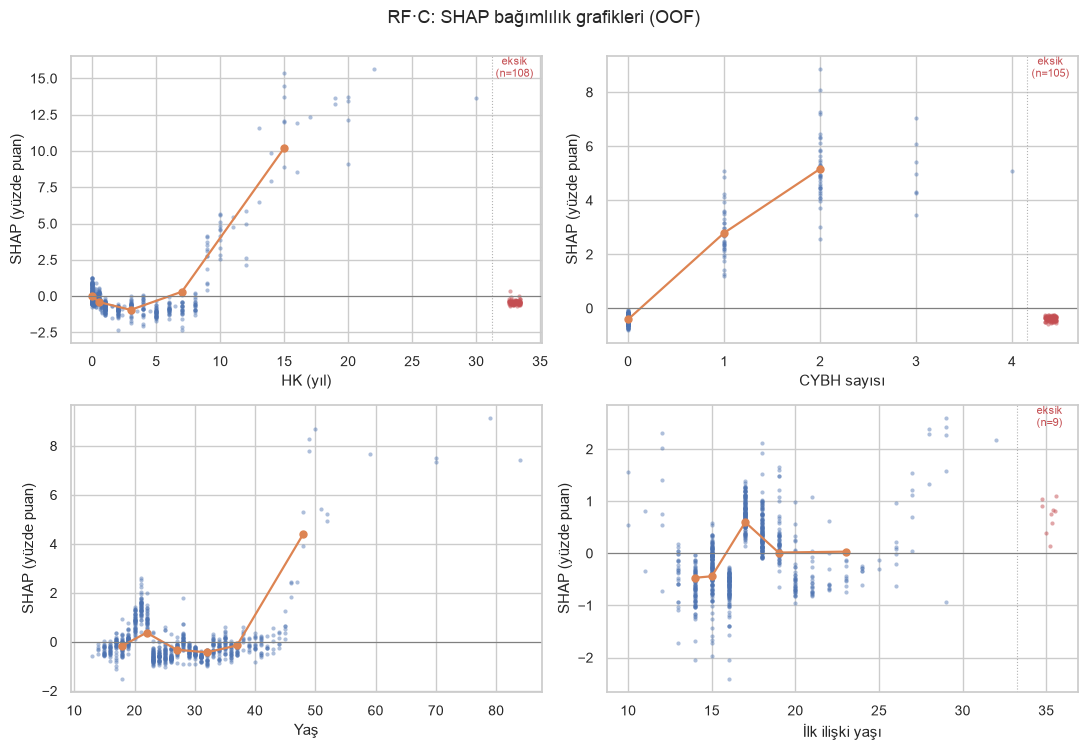


HK (yıl)
                 n  poz  ort_SHAP_yp  gözlenen +%
x                                                
(-0.01, 0.0]   269   19         0.01         7.06
(0.0, 1.0]     224   18        -0.40         8.04
(1.0, 5.0]     143    5        -0.95         3.50
(5.0, 10.0]     87    6         0.31         6.90
(10.0, 100.0]   27    7        10.21        25.93

CYBH sayısı
                n  poz  ort_SHAP_yp  gözlenen +%
x                                               
(-0.01, 0.0]  674   41        -0.40         6.08
(0.0, 1.0]     34    5         2.79        14.71
(1.0, 100.0]   45    7         5.17        15.56

Yaş
             n  poz  ort_SHAP_yp  gözlenen +%
x                                            
(0, 19]    179    6        -0.15         3.35
(19, 24]   214   16         0.38         7.48
(24, 29]   180   12        -0.32         6.67
(29, 34]   132    7        -0.42         5.30
(34, 44]   130   10        -0.14         7.69
(44, 100]   23    4         4.41        17.39

İlk iliş

In [7]:
araliklar = {"Yaş": [0, 19, 24, 29, 34, 44, 100], "HK (yıl)": [-0.01, 0, 1, 5, 10, 100],
             "İlk ilişki yaşı": [0, 14, 16, 18, 20, 100], "Gebelik sayısı": [-0.01, 1, 2, 3, 4, 100],
             "Partner sayısı": [0, 1, 2, 3, 100], "CYBH sayısı": [-0.01, 0, 1, 100]}

def aralik_ozeti(f):
    # Cevaplayan hastalarda, değer aralığına göre hasta sayısı, pozitif sayısı ve ortalama SHAP (yüzde puan).
    g = pd.DataFrame({"x": D[f], "shap": SV[f] * 100, "y": y}).dropna()
    t = g.groupby(pd.cut(g["x"], araliklar[f]), observed=True).agg(
        n=("y", "size"), poz=("y", "sum"), x_medyan=("x", "median"), ort_SHAP_yp=("shap", "mean"))
    t["gözlenen +%"] = t["poz"] / t["n"] * 100
    return t

ilk4 = [f for f in onem.index if f in [TR[c] for c in NUMERIC]][:4]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, f in zip(axes.ravel(), ilk4):
    x, s = D[f].to_numpy(dtype=float), SV[f].to_numpy() * 100
    var = ~np.isnan(x)
    ax.scatter(x[var], s[var], s=9, alpha=0.45, color=sns.color_palette()[0], linewidths=0)
    t = aralik_ozeti(f)
    ax.plot(t["x_medyan"], t["ort_SHAP_yp"], "o-", color=sns.color_palette()[1], lw=1.6, ms=5)
    if (~var).any():
        x_eksik = np.nanmax(x) * 1.10
        rng = np.random.default_rng(0)
        ax.scatter(x_eksik + rng.uniform(-0.015, 0.015, (~var).sum()) * np.nanmax(x), s[~var], s=9, alpha=0.5,
                   color=sns.color_palette()[3], linewidths=0)
        ax.axvline(np.nanmax(x) * 1.04, color="0.7", lw=0.8, ls=":")
        ax.text(x_eksik, ax.get_ylim()[1], f"eksik\n(n={(~var).sum()})", ha="center", va="top", fontsize=8, color=sns.color_palette()[3])
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(f)
    ax.set_ylabel("SHAP (yüzde puan)")
fig.suptitle("RF·C: SHAP bağımlılık grafikleri (OOF)", y=0.995)
plt.tight_layout()
plt.savefig(FIG / "05_shap_bagimlilik.png", dpi=150)
plt.show()

# Grafikleri sayıyla okumak için: değer aralıklarına göre ortalama SHAP (yalnızca cevaplayanlar)
for f in ilk4:
    print(f"\n{f}"); print(aralik_ozeti(f).drop(columns="x_medyan").round(2).to_string())

**Yorum:**
- **HK yılı doğrusal değil:** ≈8 yıla kadar katkı sıfır ya da hafif negatif; 10 yılın üzerinde hızla artıyor (ortalama ≈+10 yp). Bu aralıkta 27 hasta var ve 7'si pozitif (%26). Uzun süreli hormonal kontraseptif kullanımıyla serviks kanseri riski arasındaki ilişki literatürde de bildiriliyor; ama buradaki eğri 27 hastaya dayanıyor ve nedensellik göstermez.
- **CYBH sayısı basamak basamak artıyor:** 0 → hafif negatif, 1 → ≈+3 yp, 2 ve üzeri → ≈+5 yp. Gözlenen pozitif oranı da aynı yönde (%6 → %15).
- **Yaş:** 45 yaşına kadar etki küçük (±0.5 yp); 45 üzerindeki 23 hastada belirgin artış (≈+4 yp, gözlenen %17). 20–24 yaş civarındaki küçük tümsek, o aralıktaki biraz yüksek pozitif oranını (%7.5) izliyor.
- **İlk ilişki yaşı:** 17–18 yaşta küçük bir tümsek (≈+0.6 yp) dışında düzenli bir eğilim yok. Klinik olarak beklenen "erken yaş → yüksek risk" örüntüsü bu veride **görünmüyor**.
- **Dikkat:** Yaş ve ilk ilişki yaşındaki ±1 yp'lik iniş çıkışlar büyük olasılıkla gürültü. 55 pozitifle bu ince yapıyı yorumlamak doğru olmaz; güvenle söylenebilecek olan yalnızca kaba eğilimlerdir (uzun HK kullanımı, CYBH öyküsü, ileri yaş).
- **Kırmızı noktalar:** HK ve CYBH'de eksik hastaların doldurulmuş değeri de hafif **negatif** katkı alıyor. Bunun ne anlama geldiğini bir sonraki bölümde ayırıyoruz.

## 5. "Soruyu cevaplamamak" modelde ne kadar ağırlık taşıyor?

02'de hormonal kontraseptif (HK) sorusunu cevaplamayan 108 hastanın hiçbirinde biyopsinin pozitif çıkmadığını, 04'te de modelin bu hastalara belirgin şekilde düşük risk verdiğini gördük. SHAP ile bu düşüşün **nereden geldiğini** ayırabiliriz.

Eksik bir değer modele iki yoldan ulaşır:

1. **Gösterge:** `Eksik: HK = 1` sütunu doğrudan "bu soru cevaplanmadı" der.
2. **Doldurulmuş değer:** Eksik HK yılı medyanla doldurulur. Model bu değeri de bir öznitelik değeri olarak görür ve ona bir SHAP katkısı verir.

Her hastanın SHAP toplamını üç parçaya ayırıyoruz: **gösterge** sütunlarının katkısı, o hastada **doldurulmuş** özniteliklerin katkısı ve **gerçekten gözlenen** özniteliklerin katkısı. İlk ikisinin toplamı, eksikliğin modeldeki toplam etkisidir.

In [8]:
hk_eksik = df["Hormonal Contraceptives (years)"].isna().to_numpy()

def parcala(S, n_oz=len(OZ)):
    # SHAP toplamını (yüzde puan) gösterge / doldurulmuş / gözlenen parçalarına ayırır.
    oz = S[:, :n_oz] * 100
    return pd.DataFrame({"gösterge": S[:, n_oz:].sum(axis=1) * 100,
                         "doldurulmuş değer": np.where(EKSIK, oz, 0).sum(axis=1),
                         "gözlenen değer": np.where(~EKSIK, oz, 0).sum(axis=1)})

rows = []
for model, S, tb in [("RF·C (grup göstergeli)", S_C.mean(axis=0), taban_C.mean(axis=0)),
                     ("RF·A (göstergesiz)", S_A.mean(axis=0), taban_A.mean(axis=0))]:
    par = parcala(S)
    for ad, m in [("HK cevapsız", hk_eksik), ("HK cevaplı", ~hk_eksik)]:
        r = par[m].mean()
        rows.append({"model": model, "hasta grubu": f"{ad} (n={m.sum()})", "taban %": tb[m].mean() * 100,
                     "gösterge": r["gösterge"], "doldurulmuş değer": r["doldurulmuş değer"], "gözlenen değer": r["gözlenen değer"],
                     "eksiklik toplamı": r["gösterge"] + r["doldurulmuş değer"],
                     "ort. tahmin %": (tb[m] + S[m].sum(axis=1)).mean() * 100, "gözlenen +%": y[m].mean() * 100})
eksik_tab = pd.DataFrame(rows).set_index(["model", "hasta grubu"])
eksik_tab.to_csv(TAB / "05_shap_eksiklik.csv", encoding="utf-8-sig")

# Doldurulmuş değer neden bilgi taşıyabiliyor? Medyan, cevaplayan hastalarda ne kadar yaygın bir değer?
for c in ["Hormonal Contraceptives (years)", "IUD (years)", "STDs (number)"]:
    med = X[c].median()
    print(f"{TR[c]}: medyan = {med:g}; cevaplayan {X[c].notna().sum()} hastanın {(X[c] == med).sum()} tanesinde tam bu değer var")
eksik_tab.round(2)

HK (yıl): medyan = 0.5; cevaplayan 750 hastanın 25 tanesinde tam bu değer var
RİA (yıl): medyan = 0; cevaplayan 741 hastanın 658 tanesinde tam bu değer var
CYBH sayısı: medyan = 0; cevaplayan 753 hastanın 674 tanesinde tam bu değer var


taban %  gösterge  doldurulmuş değer  gözlenen değer  eksiklik toplamı  ort. tahmin %  gözlenen +%
model                  hasta grubu                                                                                                            
RF·C (grup göstergeli) HK cevapsız (n=108)     6.41     -2.66              -1.24           -0.14             -3.90           2.38         0.00
                       HK cevaplı (n=750)      6.41      0.40              -0.03            0.20              0.37           6.99         7.33
RF·A (göstergesiz)     HK cevapsız (n=108)     6.41      0.00              -1.85           -0.10             -1.85           4.46         0.00
                       HK cevaplı (n=750)      6.41      0.00              -0.02            0.30             -0.02           6.69         7.33

HK cevapsız hastalarda riski en çok düşüren ve artıran sütunlar:
                 ort SHAP (yp)  bu grupta doldurulmuş %
Eksik: HK                -2.13                      NaN
HK (yıl)                 -0.42                   100.00
Eksik: RİA               -0.30                      NaN
Eksik: CYBH              -0.26                      NaN
Dx: Kanser               -0.18                     0.00
CYBH sayısı              -0.13                    87.96
İlk ilişki yaşı           0.01                     0.93
Eksik: Gebelik            0.01                      NaN
Eksik: Sigara             0.03                      NaN


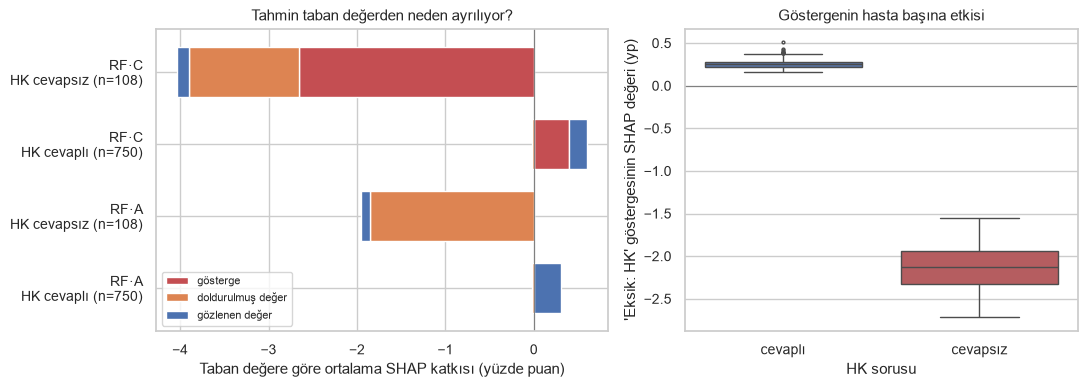

In [9]:
# HK cevapsız 108 hastada: hangi sütun ne kadar katkı veriyor? (RF·C, yüzde puan)
detay = (SV[hk_eksik].mean() * 100).sort_values()
detay = pd.DataFrame({"ort SHAP (yp)": detay, "bu grupta doldurulmuş %": [
    (EKSIK[hk_eksik][:, OZ.index(f)].mean() * 100 if f in OZ else np.nan) for f in detay.index]})
print("HK cevapsız hastalarda riski en çok düşüren ve artıran sütunlar:")
print(pd.concat([detay.head(6), detay.tail(3)]).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
p = eksik_tab[["gösterge", "doldurulmuş değer", "gözlenen değer"]].copy()
p.index = [f"{m.split(' ')[0]}\n{g}" for m, g in p.index]
p.plot.barh(stacked=True, ax=ax, color=[sns.color_palette()[3], sns.color_palette()[1], sns.color_palette()[0]], width=0.7)
ax.axvline(0, color="grey", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Taban değere göre ortalama SHAP katkısı (yüzde puan)")
ax.set_title("Tahmin taban değerden neden ayrılıyor?")
ax.legend(fontsize=8)

ax = axes[1]
g = pd.DataFrame({"SHAP": SV["Eksik: HK"] * 100, "HK sorusu": np.where(hk_eksik, "cevapsız", "cevaplı")})
sns.boxplot(data=g, x="HK sorusu", y="SHAP", order=["cevaplı", "cevapsız"], ax=ax, fliersize=2,
            palette={"cevaplı": sns.color_palette()[0], "cevapsız": sns.color_palette()[3]})
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("'Eksik: HK' göstergesinin SHAP değeri (yp)")
ax.set_title("Göstergenin hasta başına etkisi")
plt.tight_layout()
plt.savefig(FIG / "05_shap_eksiklik.png", dpi=150)
plt.show()

**Yorum:**
- **Düşüşün neredeyse tamamı eksiklikten geliyor.** HK sorusunu cevaplamayan 108 hastada RF·C'nin tahmini taban değerden (%6.4) ortalama %2.4'e iniyor. Bu ≈4.0 yp'lik düşüşün **3.9 yp'si** eksiklik kaynaklı (gösterge −2.7, doldurulmuş değerler −1.2); hastaların gerçekten gözlenen özellikleri (yaş, partner sayısı vb.) yalnızca −0.1 yp katkı veriyor.
- **Göstergenin içinde asıl yük `Eksik: HK`'da** (−2.1 yp); `Eksik: RİA` ve `Eksik: CYBH` ≈−0.3'er yp ekliyor. Üçü aynı hastalarda birlikte 1 olduğu için model yükü aralarında bölüştürüyor; toplam etkiyi **blok** olarak okumak daha doğru.
- **Göstergeyi çıkarmak eksikliği modelden gizlemiyor.** Göstergesiz RF·A da aynı hastaların riskini 1.9 yp düşürüyor ve bunun tamamı **doldurulmuş değerlerden** geliyor. Nedeni: HK yılının medyanı 0.5 ve cevaplayan 750 hastanın yalnızca 25'inde tam bu değer var. Yani "HK = 0.5 yıl" pratikte "soru cevaplanmadı" demek; ağaç modeli bunu ayırabiliyor.
- **04'teki bir yorumun düzeltilmesi:** 04'te RF·A'nın bu hastalara daha düşük risk vermesini "daha genç olmaları gibi gözlenen farklara" bağlamıştık. SHAP ayrıştırması bunu desteklemiyor: gözlenen özniteliklerin katkısı yalnızca −0.1 yp. Düşüşün kaynağı yaş değil, medyanla doldurulmuş değerlerin kendisi.
- **Cevaplayanlar da etkileniyor:** Gösterge 0 olduğunda her hastanın riski ≈+0.4 yp artıyor. Küçük bir etki, ama 750 hastanın hepsine uygulanıyor.

## 6. Tek hasta düzeyinde açıklamalar

Genel örüntüler, tek bir hastanın tahmininin nasıl oluştuğunu göstermez. Üç örnek hasta seçiyoruz: modelin **en yüksek risk** verdiği hasta, HK sorusunu cevaplamayanlar arasında **tipik** (medyan riskli) bir hasta ve modelin **kaçırdığı** (en düşük risk verdiği) biyopsi pozitif hasta.

Her çubuk bir özniteliğin katkısıdır (kırmızı = riski artırıyor, mavi = azaltıyor). Etiketlerde hastanın ham değeri yazıyor; `eksik` doldurulmuş değerdir.

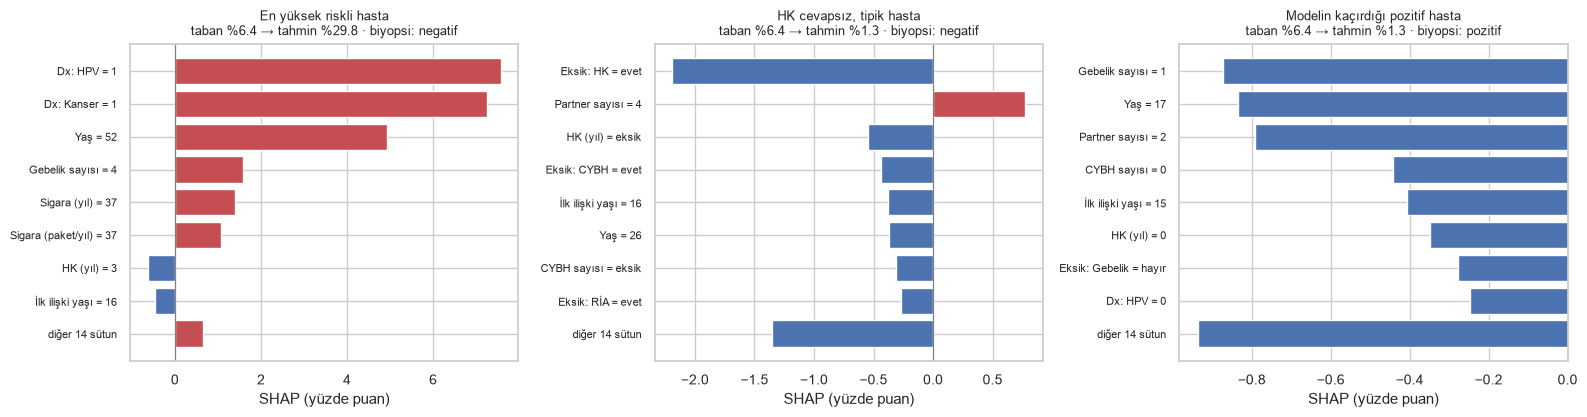

Biyopsi pozitif 55 hastanın tahmin edilen riski: medyan %8.6, 20 tanesi genel oranın (%6.4) altında


In [10]:
def hasta_grafik(ax, i, baslik, k=8):
    s = SV.iloc[i] * 100
    sira = s.abs().sort_values(ascending=False).index
    ust, kalan = list(sira[:k]), list(sira[k:])
    def etiket(f):
        v = D.loc[D.index[i], f]
        if f in GOST:
            return f"{f} = {'evet' if v == 1 else 'hayır'}"
        return f"{f} = eksik" if pd.isna(v) else f"{f} = {v:g}"
    ad = [etiket(f) for f in ust] + [f"diğer {len(kalan)} sütun"]
    deger = [s[f] for f in ust] + [s[kalan].sum()]
    ax.barh(ad[::-1], deger[::-1], color=[sns.color_palette()[3] if v > 0 else sns.color_palette()[0] for v in deger[::-1]])
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("SHAP (yüzde puan)")
    ax.set_title(f"{baslik}\ntaban %{taban[i]*100:.1f} → tahmin %{P[i]*100:.1f} · biyopsi: {'pozitif' if y[i] else 'negatif'}", fontsize=9)
    ax.tick_params(axis="y", labelsize=8)

i_yuksek = int(np.argmax(P))
hk_idx = np.where(hk_eksik)[0]
i_hk = int(hk_idx[np.argsort(P[hk_idx])[len(hk_idx) // 2]])
poz = np.where(y == 1)[0]
i_kacan = int(poz[np.argmin(P[poz])])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
hasta_grafik(axes[0], i_yuksek, "En yüksek riskli hasta")
hasta_grafik(axes[1], i_hk, "HK cevapsız, tipik hasta")
hasta_grafik(axes[2], i_kacan, "Modelin kaçırdığı pozitif hasta")
plt.tight_layout()
plt.savefig(FIG / "05_shap_hasta.png", dpi=150)
plt.show()

print("Biyopsi pozitif 55 hastanın tahmin edilen riski: "
      f"medyan %{np.median(P[poz])*100:.1f}, {int((P[poz] < prev).sum())} tanesi genel oranın (%{prev*100:.1f}) altında")

**Yorum:**
- **En yüksek riskli hasta (%29.8) aslında negatif.** Tahmini önceki tanılar (`Dx: HPV`, `Dx: Kanser`) ve yaş (52) sürüklüyor. Model "önceden tanı almış, ileri yaşta hasta" profiline en yüksek riski veriyor; bu makul, ama bu hastada tutmuyor.
- **HK cevapsız tipik hasta (%1.3):** Riski düşüren en büyük tek katkı `Eksik: HK` (≈−2.2 yp); doldurulmuş HK ve CYBH değerleri ile diğer blok göstergeleri de aynı yönde. Hastanın kendi bildirdiği tek belirgin risk işareti (4 partner) bunu dengeleyemiyor.
- **Kaçırılan pozitif hasta (%1.3):** 17 yaşında, 1 gebelik, CYBH yok, HK kullanmıyor. Hiçbir sütun riski artırmıyor; model bu hastayı düşük riskli saymakta "haklı" görünüyor ama biyopsi pozitif. Bu tek bir örnek değil: 55 pozitif hastanın **20'sinde** tahmin genel oranın (%6.4) altında.
- **Çıkarım:** Pozitif hastaların önemli bir kısmı, bu 15 anket özniteliği açısından negatiflerden ayırt edilemiyor. Düşük ayırt ediciliğin nedeni model seçimi değil, girdilerin taşıdığı bilginin sınırlı olması. SHAP burada modelin yanlış bir şey yaptığını değil, **yapacak bir şeyi olmadığını** gösteriyor.

## 7. Etik tartışma: "soruyu cevaplamadı → riski düşük" kuralına güvenmeli miyiz?

SHAP analizi, 04'te sorduğumuz soruyu somutlaştırdı: model mahrem soruları cevaplamayan bir hastanın riskini, hastanın **bildirdiği hiçbir şeye bakmadan** yaklaşık üçte birine indiriyor. Bu davranışı beş açıdan değerlendiriyoruz.

**1. Gösterge bir risk faktörü değil, veri toplama sürecinin izi.**
"HK sorusunu cevaplamamak" hastanın biyolojisi hakkında bir bilgi değil; anketin nasıl uygulandığı, kimin hangi koşulda cevap vermediği hakkında bir bilgi. Bu ilişki tek bir hastanede, tek bir dönemde gözlendi. Başka bir klinikte (farklı anketör, farklı mahremiyet koşulları, farklı hasta profili) yönü bile değişebilir: 02'de dışlayamadığımız MNAR senaryosunda, CYBH öyküsü olanlar tam da bu yüzden soruyu atlıyor olabilir.

**2. Dayandığı kanıt zayıf.**
Örüntü 0/108 gözlemine dayanıyor; pozitif oranının %95 güven aralığı %0–3.4. Model bu grubun riskini ≈%2.4 olarak tahmin ediyor, yani aralığın içinde ve "sıfır" demiyor. Bu, kalibrasyon açısından savunulabilir. Ama aynı model `Eksik: Gebelik` için **ters yönde** ve yalnızca 7 pozitife dayanan bir örüntüyü de öğrendi. İkisine aynı güveni duymak tutarlı olmaz.

**3. Yanlış teşvik yaratır.**
Bu model klinikte kullanılırsa, **daha az bilgi veren hasta daha düşük risk puanı alır.** Biyopsi kararı puana bağlanırsa, mahrem soruları cevaplamak istemeyen hastalar sistematik olarak daha az biyopsiye yönlendirilir. Bir tarama aracında bilgi vermemenin "ödüllendirilmesi" kabul edilemez; üstelik bu hastalar hakkında en az şey bildiğimiz hastalardır.

**4. Etkilenen grup rastgele değil.**
02'de cevaplamayanların daha genç olduğunu gördük (medyan 23'e karşı 26; ≤19 yaşta %19.6, 40+ yaşta %4.6). Model, mahremiyet kaygısı yüksek genç hastaların riskini topluca düşürüyor. Bu grup için ayrı bir doğrulama yapılamıyor, çünkü içinde hiç pozitif yok.

**5. Göstergeyi çıkarmak çözüm değil.**
5. bölümde gördüğümüz gibi göstergesiz model de eksikliği doldurulmuş değerlerden tanıyor (−1.9 yp). Göstergeyi kaldırmak davranışı ortadan kaldırmaz, yalnızca **görünmez** kılar. Açık bir gösterge en azından etkinin ölçülmesine, raporlanmasına ve izlenmesine izin veriyor. Bu yüzden son model olarak RF·C'yi koruyoruz.

### Önceki tanılar (Dx) hakkında ayrı bir uyarı

Modelin en yüksek riskleri `Dx: Kanser` ve `Dx: HPV` sütunlarından geliyor (≈6–11 yp). Veri açıklaması bu tanıların **ne zaman** konduğunu söylemiyor. Biyopsiden önce biliniyorlarsa meşru birer öykü bilgisidir; biyopsinin sonucuna göre girilmişlerse sızıntıdır. Raporda bu varsayım açıkça yazılmalı ve Dx sütunları olmadan bir duyarlılık analizi yapılmalı.

### Öneriler

- Model, mahrem soruları cevaplamayan hastalarda biyopsi yönlendirmesini **azaltmak** için kullanılmamalı. En güvenli kural: blok eksik olan hastada model puanı gösterilmez, standart tarama yolu izlenir.
- Eksiklik göstergesinin etkisi raporda açıkça verilmeli (bu defterdeki ayrıştırma tablosu).
- Dış doğrulama olmadan bu ilişki genellenmemeli; farklı bir merkezde ilk bakılacak şey, cevaplamayan grubun gözlenen pozitif oranıdır.
- Model kullanılacaksa cevaplamayan hastaların oranı ve sonuçları sürekli izlenmeli.

## 8. Sonuç

| Soru | Cevap |
|---|---|
| Model neye dayanıyor? | Tek bir baskın öznitelik yok. Grup olarak CYBH (≈%23), demografi / cinsel öykü (≈%22), hormonal kontraseptif (≈%16) ve önceki tanılar (≈%14). |
| En belirgin örüntüler? | 10 yılın üzerinde HK kullanımı (≈+10 yp), CYBH öyküsü (≈+3–5 yp), önceki HPV / kanser tanısı (≈+6–11 yp), 45 yaş üstü (≈+4 yp). |
| Eksiklik ne kadar ağırlık taşıyor? | Göstergeler toplam önemin ≈%12'si. HK sorusunu cevaplamayan hastada risk %6.4'ten %2.4'e iniyor; bu düşüşün 3.9 / 4.0 yp'si eksiklik kaynaklı. |
| Göstergeyi çıkarmak bunu önler mi? | **Hayır.** Göstergesiz model de doldurulmuş değerler üzerinden riski 1.9 yp düşürüyor. |
| Açıklamalar kararlı mı? | **Evet.** Önem sıralaması 10 tekrar arasında neredeyse aynı (Spearman ρ ≈ 0.99). |
| Model neden pozitifleri kaçırıyor? | Kaçırılan pozitiflerde riski artıran hiçbir öznitelik yok; 55 pozitifin 20'si genel oranın altında risk alıyor. Sınır modelde değil, girdilerde. |
| Bu davranışa güvenmeli miyiz? | Eksiklik kuralı için **hayır**: tek merkeze özgü, 0/108 gözlemine dayanıyor ve bilgi vermeyeni ödüllendiriyor. |

### Sınırlılıklar

- **SHAP modeli açıklar, nedenselliği değil.** Buradaki hiçbir bulgu "X riski artırır" şeklinde okunmamalı.
- **Zayıf model, zayıf açıklama.** ROC-AUC 0.70 olan bir modelin dayandığı örüntülerin bir kısmı gürültü. Yalnızca kaba eğilimler yorumlandı.
- **İlişkili öznitelikler katkıyı böler** (sigara yılı ve paket/yıl; `Dx: Kanser` ve `Dx: HPV`; üç blok göstergesi). Bu yüzden grup düzeyinde önem de verildi.
- **Küçük alt gruplar:** 10 yıl üzeri HK (27 hasta), 45 yaş üstü (23 hasta), Dx pozitif (18 hasta). Bu gruplardaki büyük SHAP değerleri az sayıda hastaya dayanıyor.
- **`TreeExplainer` ağaç yollarına göre koşullar** (`tree_path_dependent`). Öznitelikler bağımsızmış gibi davranan yöntemler (ör. arka plan verisiyle müdahaleci SHAP) biraz farklı değerler verebilir.

### Sonraki adımlar

- Dx sütunları olmadan duyarlılık analizi (zamanlama varsayımının etkisi).
- LR·C için iç çapraz doğrulamayla düzenlileştirme (04'te açık kalan konu).
- Ara rapor (2 Aralık): Yöntem ve Sonuçlar bölümlerini LaTeX'e taşımak; bu defterden `05_shap_onem.png`, `05_shap_beeswarm.png` ve `05_shap_eksiklik.png` rapora girecek.